# FOD-A Exploratory Data Analysis

This notebook examines the complete FOD-A dataset after construction of the sequence-aware, leakage-resistant split. The purpose is to establish evidence for later preprocessing, model selection and condition-aware evaluation decisions.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
TABLE_DIR = PROJECT_ROOT / 'reports/tables/eda'
FIGURE_DIR = PROJECT_ROOT / 'reports/figures/eda'
summary = json.loads((TABLE_DIR / 'eda_summary.json').read_text())
print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/neeliamedhani/Machine Vision


## 1. Dataset scale and annotation completeness

Every image has a corresponding Pascal VOC annotation. The corrected manifest assigns every image to exactly one partition.

In [2]:
pd.Series({
    'Images': summary['images'],
    'Annotation files': summary['annotations'],
    'Annotated objects': summary['objects'],
    'Source categories': summary['categories'],
}).to_frame('Count')

,Count
Images,33793
Annotation files,33793
Annotated objects,34472
Source categories,31


## 2. Debris-category distribution

The source categories are not equally represented. This supports treating all debris as one safety-relevant `FOD` class for the primary detector, while retaining source categories for diagnostic analysis.

,category,objects
0,Bolt,3300
1,Pliers,2884
2,Wrench,2568
3,Washer,2139
4,Wire,2138
5,PlasticPart,2008
6,LuggageTag,1686
7,Cutter,1352
8,Label,1310
9,Nut,1303


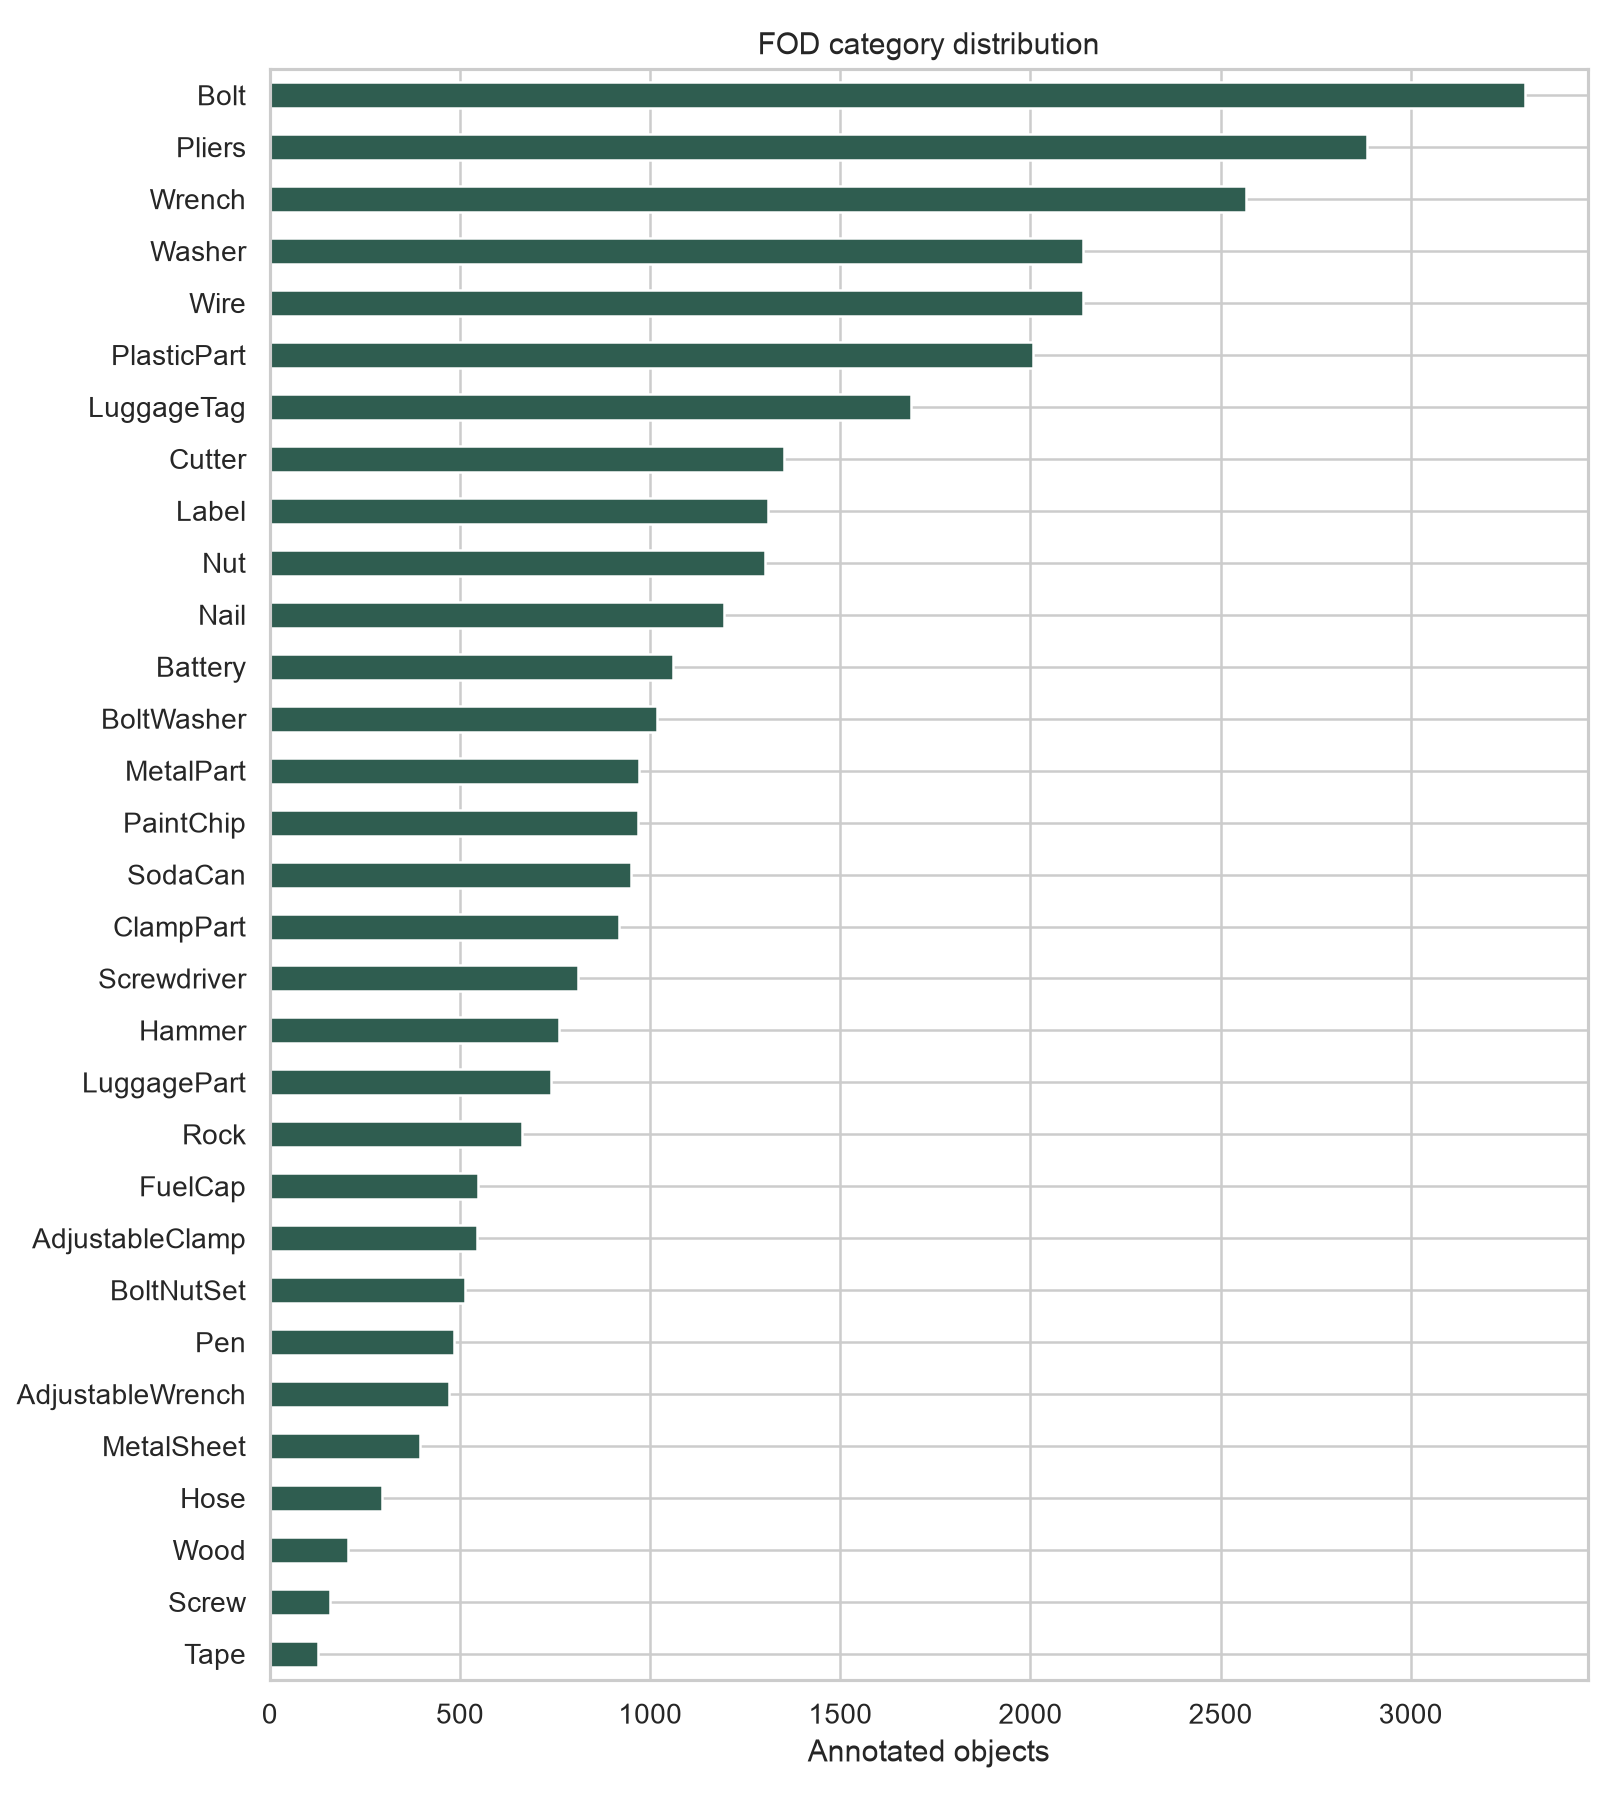

In [3]:
category_counts = pd.read_csv(TABLE_DIR / 'category_distribution.csv')
display(category_counts.head(10))
display(Image(filename=FIGURE_DIR / 'category_distribution.png'))

## 3. Lighting and weather

Lighting codes are interpreted as bright, dim and dark; weather codes are interpreted as dry and wet. These conditions are imbalanced, so aggregate detection metrics alone would conceal condition-specific failure.

/var/folders/xw/h6gs4_md7jn999tpq6j26x7c0000gn/T/ipykernel_11178/1959645089.py:4: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  }).fillna('')


,Lighting images,Weather images
Bright,16942.0,
Dark,4387.0,
Dim,12464.0,
Dry,,26577.0
Wet,,7216.0


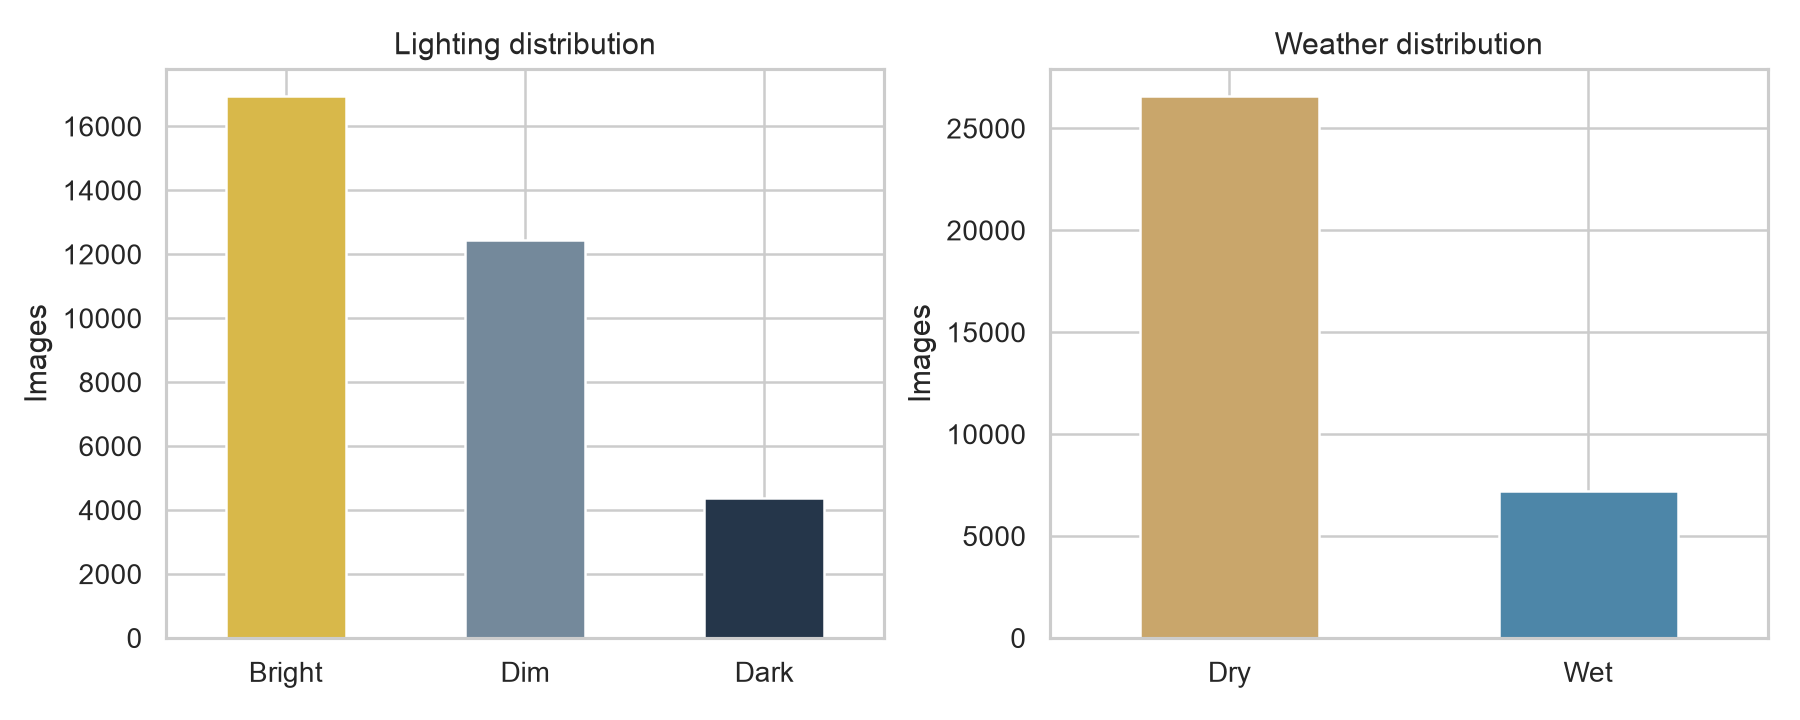

In [4]:
environment = pd.DataFrame({
    'Lighting images': pd.Series(summary['lighting_images']),
    'Weather images': pd.Series(summary['weather_images']),
}).fillna('')
display(environment)
display(Image(filename=FIGURE_DIR / 'environment_distribution.png'))

## 4. Objects per image and object size

Object sizes use the standard COCO pixel-area rule at the native 300×300 resolution: small below $32^2$ pixels, medium from $32^2$ to below $96^2$, and large from $96^2$ pixels. This definition is fixed before modelling.

,Images
1,33114
2,679


,Objects
Small,9852
Medium,15960
Large,8660


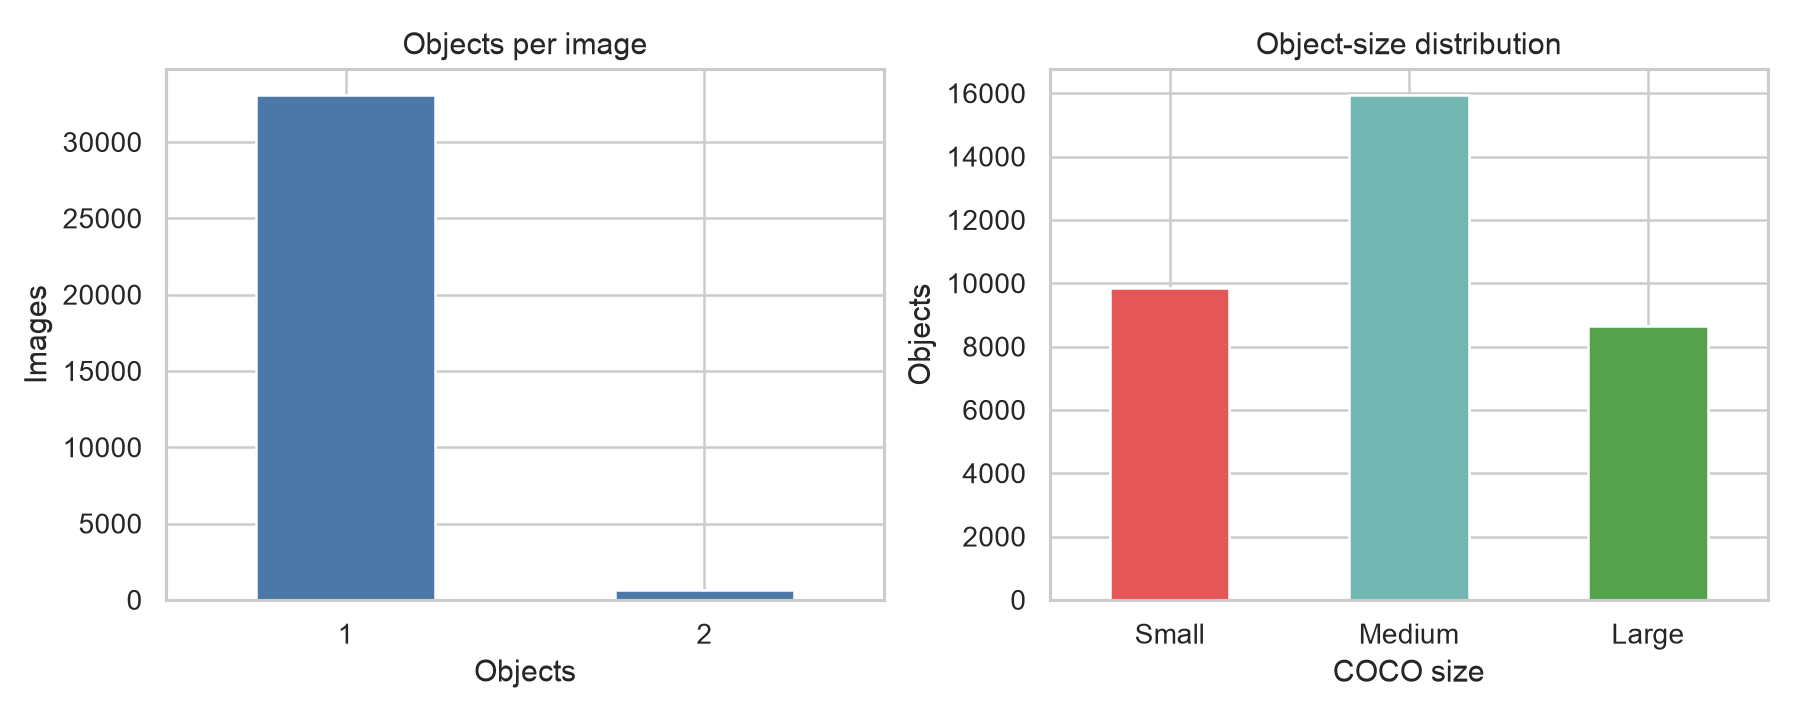

In [5]:
display(pd.Series(summary['objects_per_image'], name='Images').to_frame())
display(pd.Series(summary['object_sizes'], name='Objects').to_frame())
display(Image(filename=FIGURE_DIR / 'objects_and_sizes.png'))

## 5. Bounding-box dimensions

The wide range of widths, heights and areas confirms that the project is a multiscale detection problem. Small FOD deserves separate reporting because resizing and downsampling can remove already limited visual evidence.

In [6]:
pd.Series(summary['box_area_fraction_percentiles'], name='Area fraction').to_frame()

,Area fraction
0,0.000238
0.1,0.002419
0.25,0.009356
0.5,0.036121
0.75,0.102903
0.9,0.214863
1,0.864285


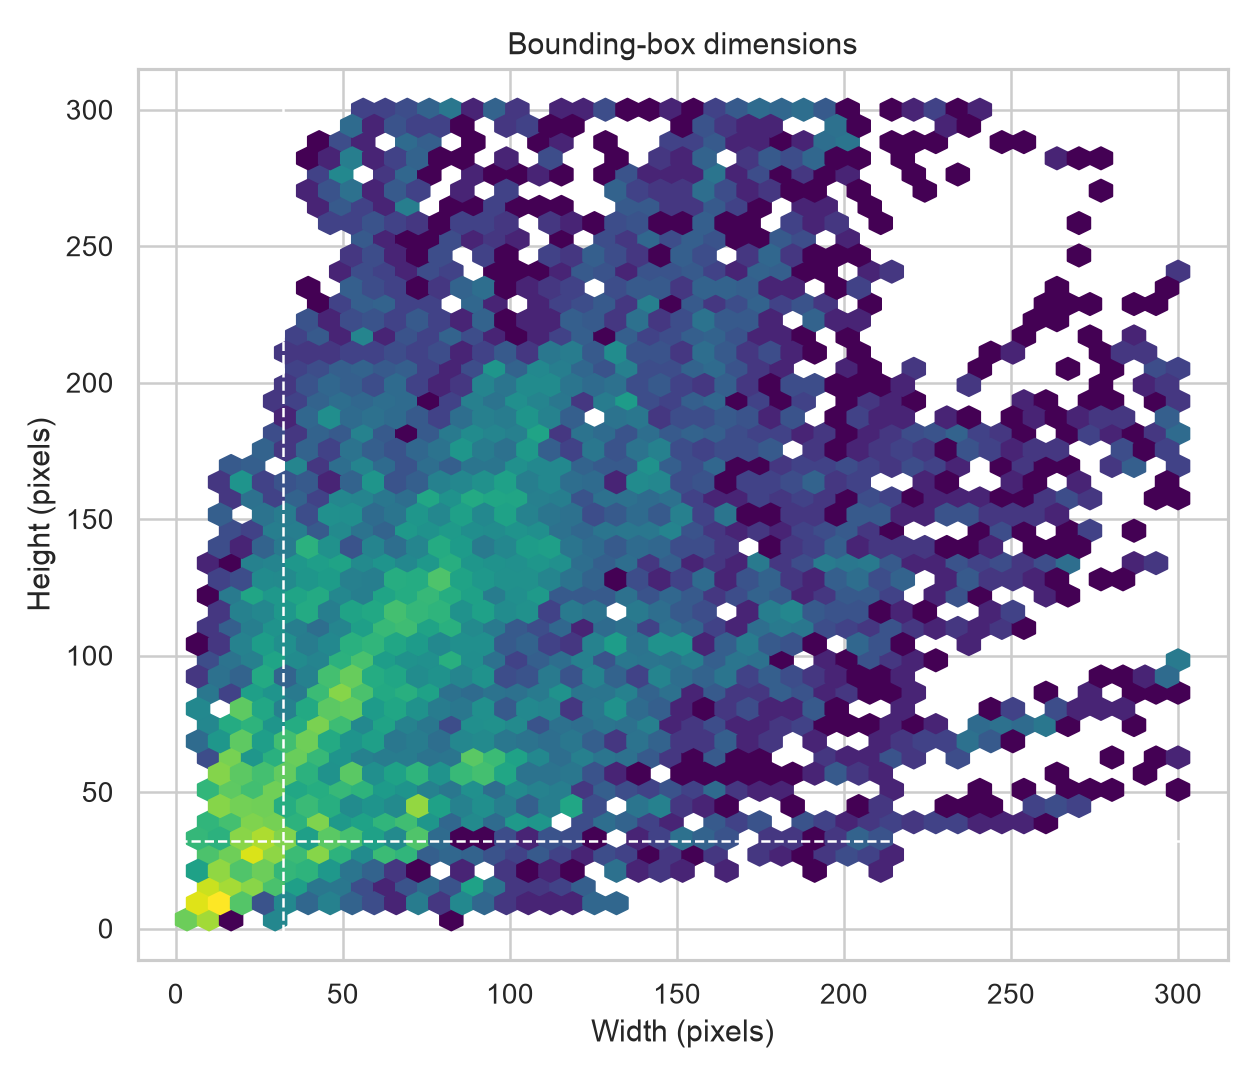

In [7]:
display(Image(filename=FIGURE_DIR / 'bounding_box_dimensions.png'))

## 6. Class–environment associations

Cramér's V measures the strength of association between source category and capture condition. Values near 0.5 indicate that category and environment are not independent. This reinforces the need for condition-aware splitting and reporting.

In [8]:
pd.Series({
    "Category–lighting Cramér's V": summary['class_lighting_cramers_v'],
    "Category–weather Cramér's V": summary['class_weather_cramers_v'],
}).to_frame('Association')

,Association
Category–lighting Cramér's V,0.5321
Category–weather Cramér's V,0.5099


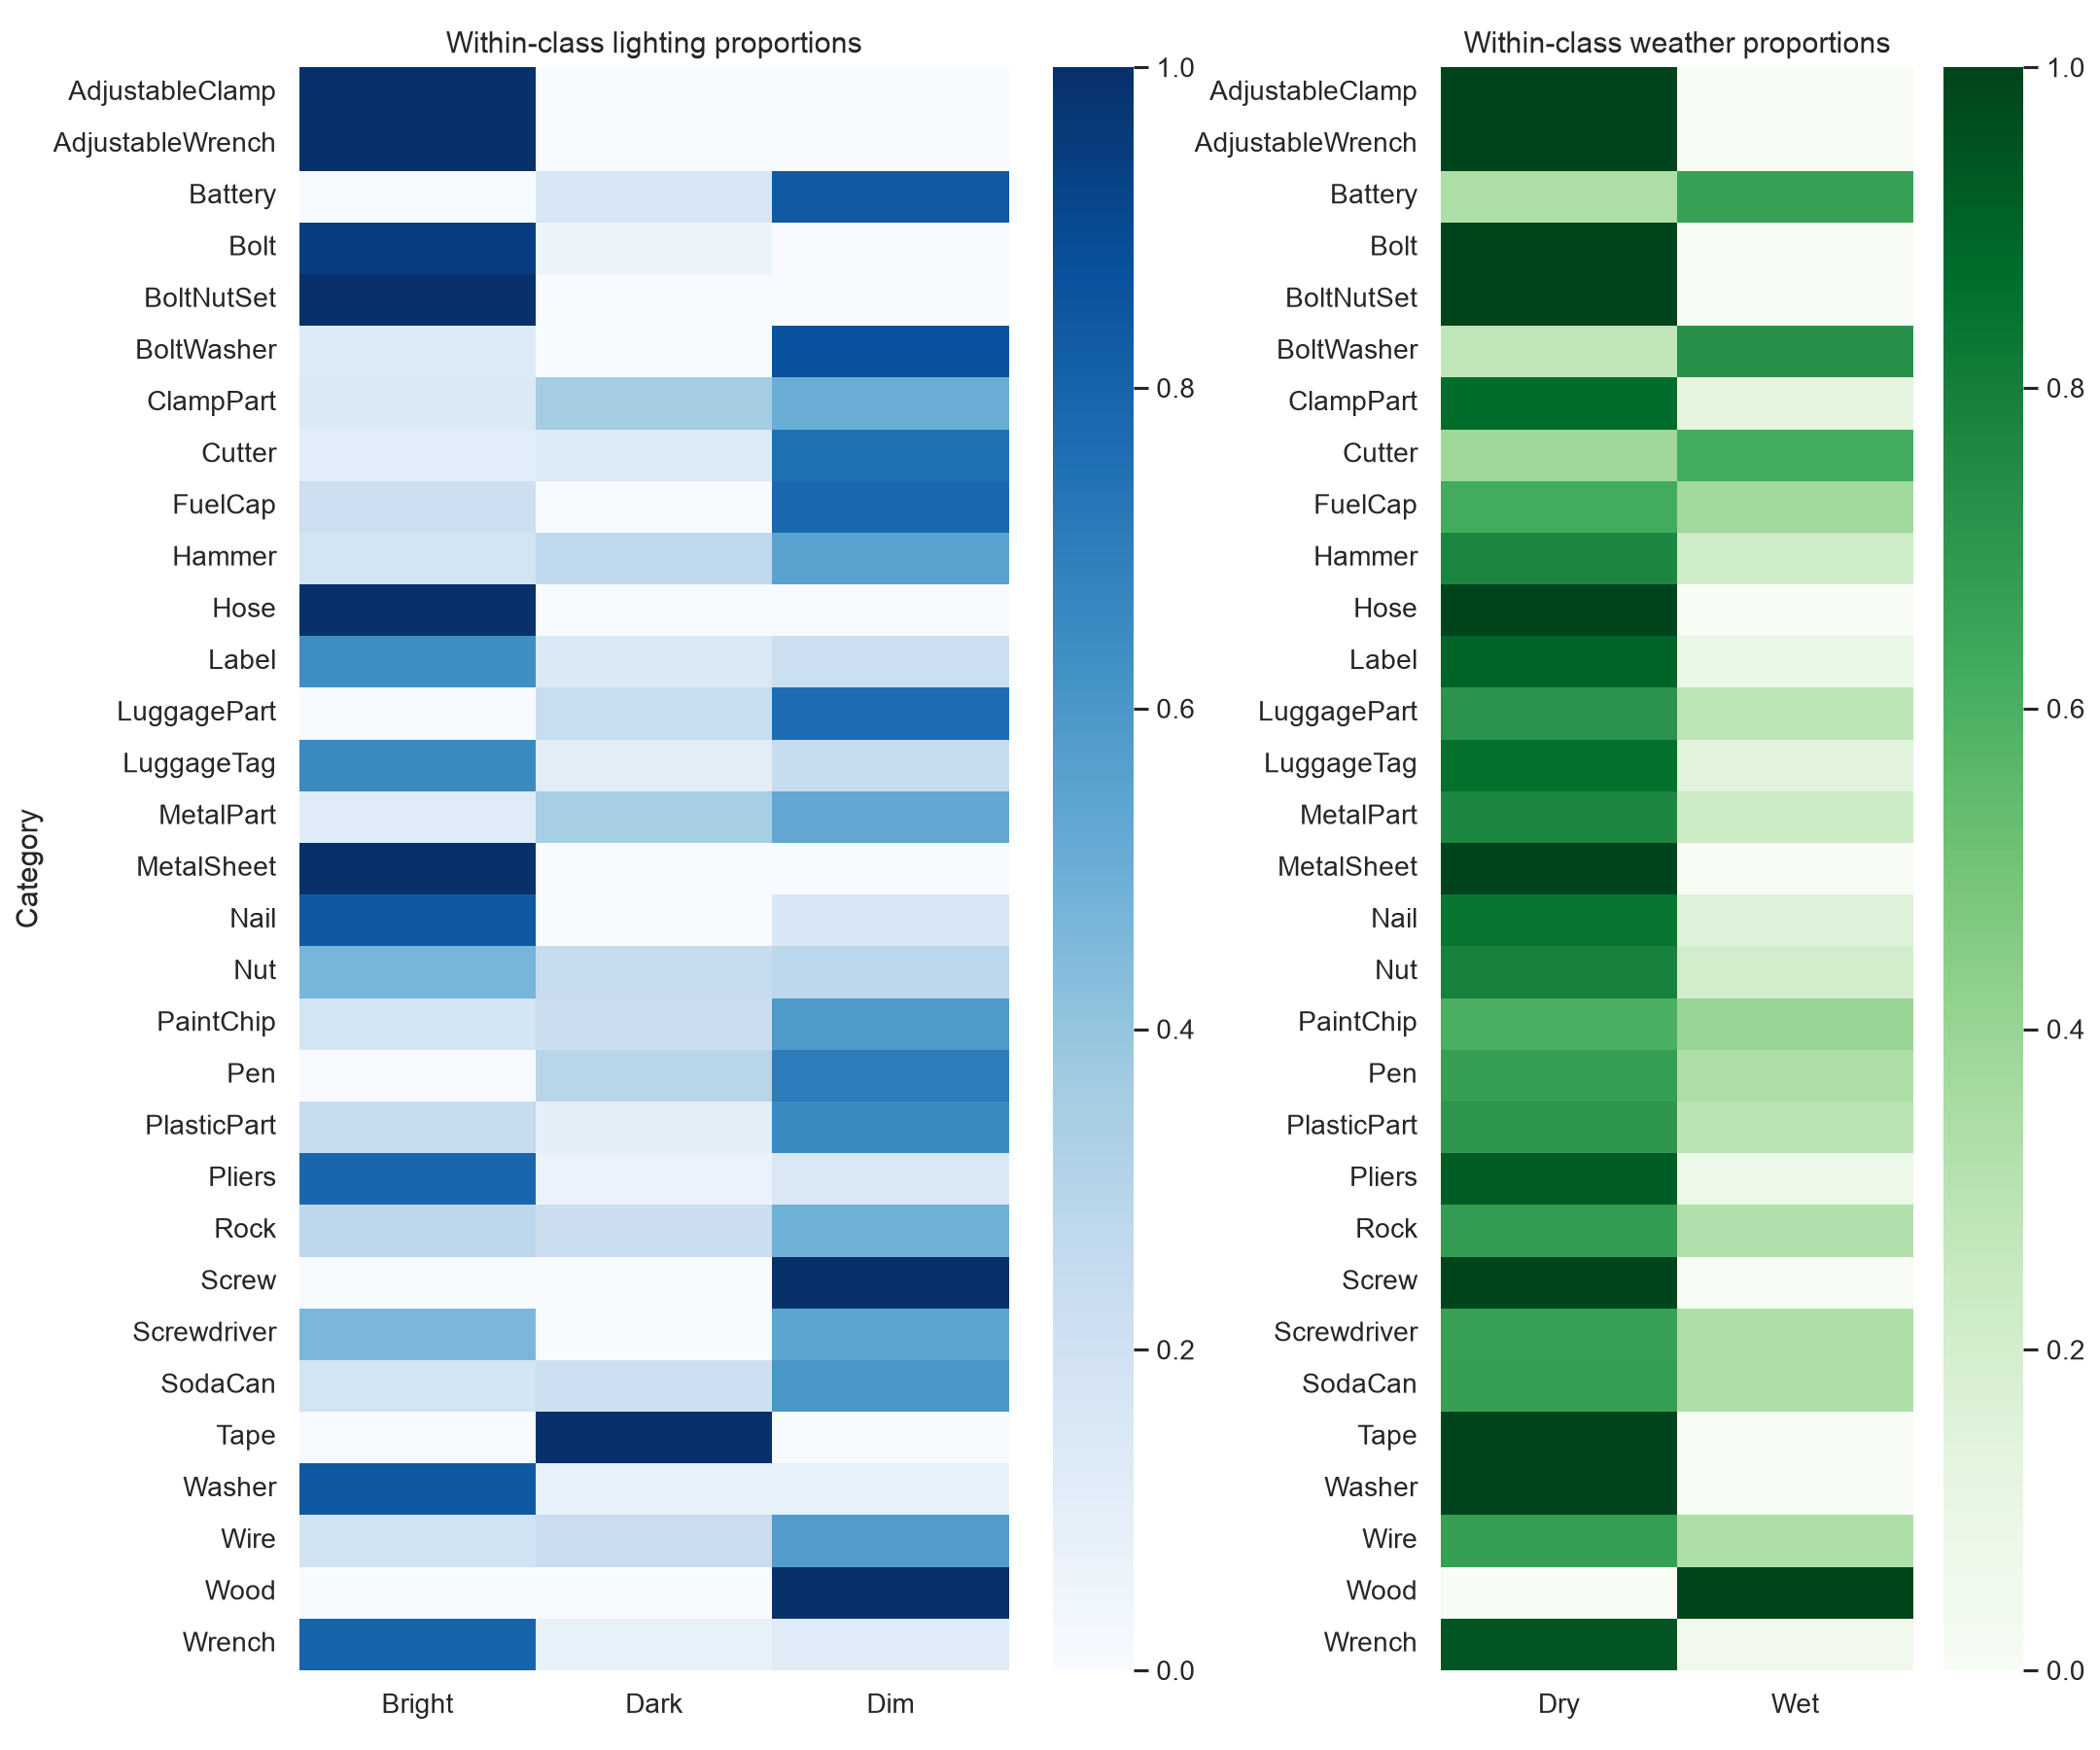

In [9]:
display(Image(filename=FIGURE_DIR / 'class_environment_associations.png'))

## 7. Representative images

Examples are selected across every available lighting–weather combination, using mid-range brightness rather than manually choosing visually attractive cases. Red boxes show the ground truth.

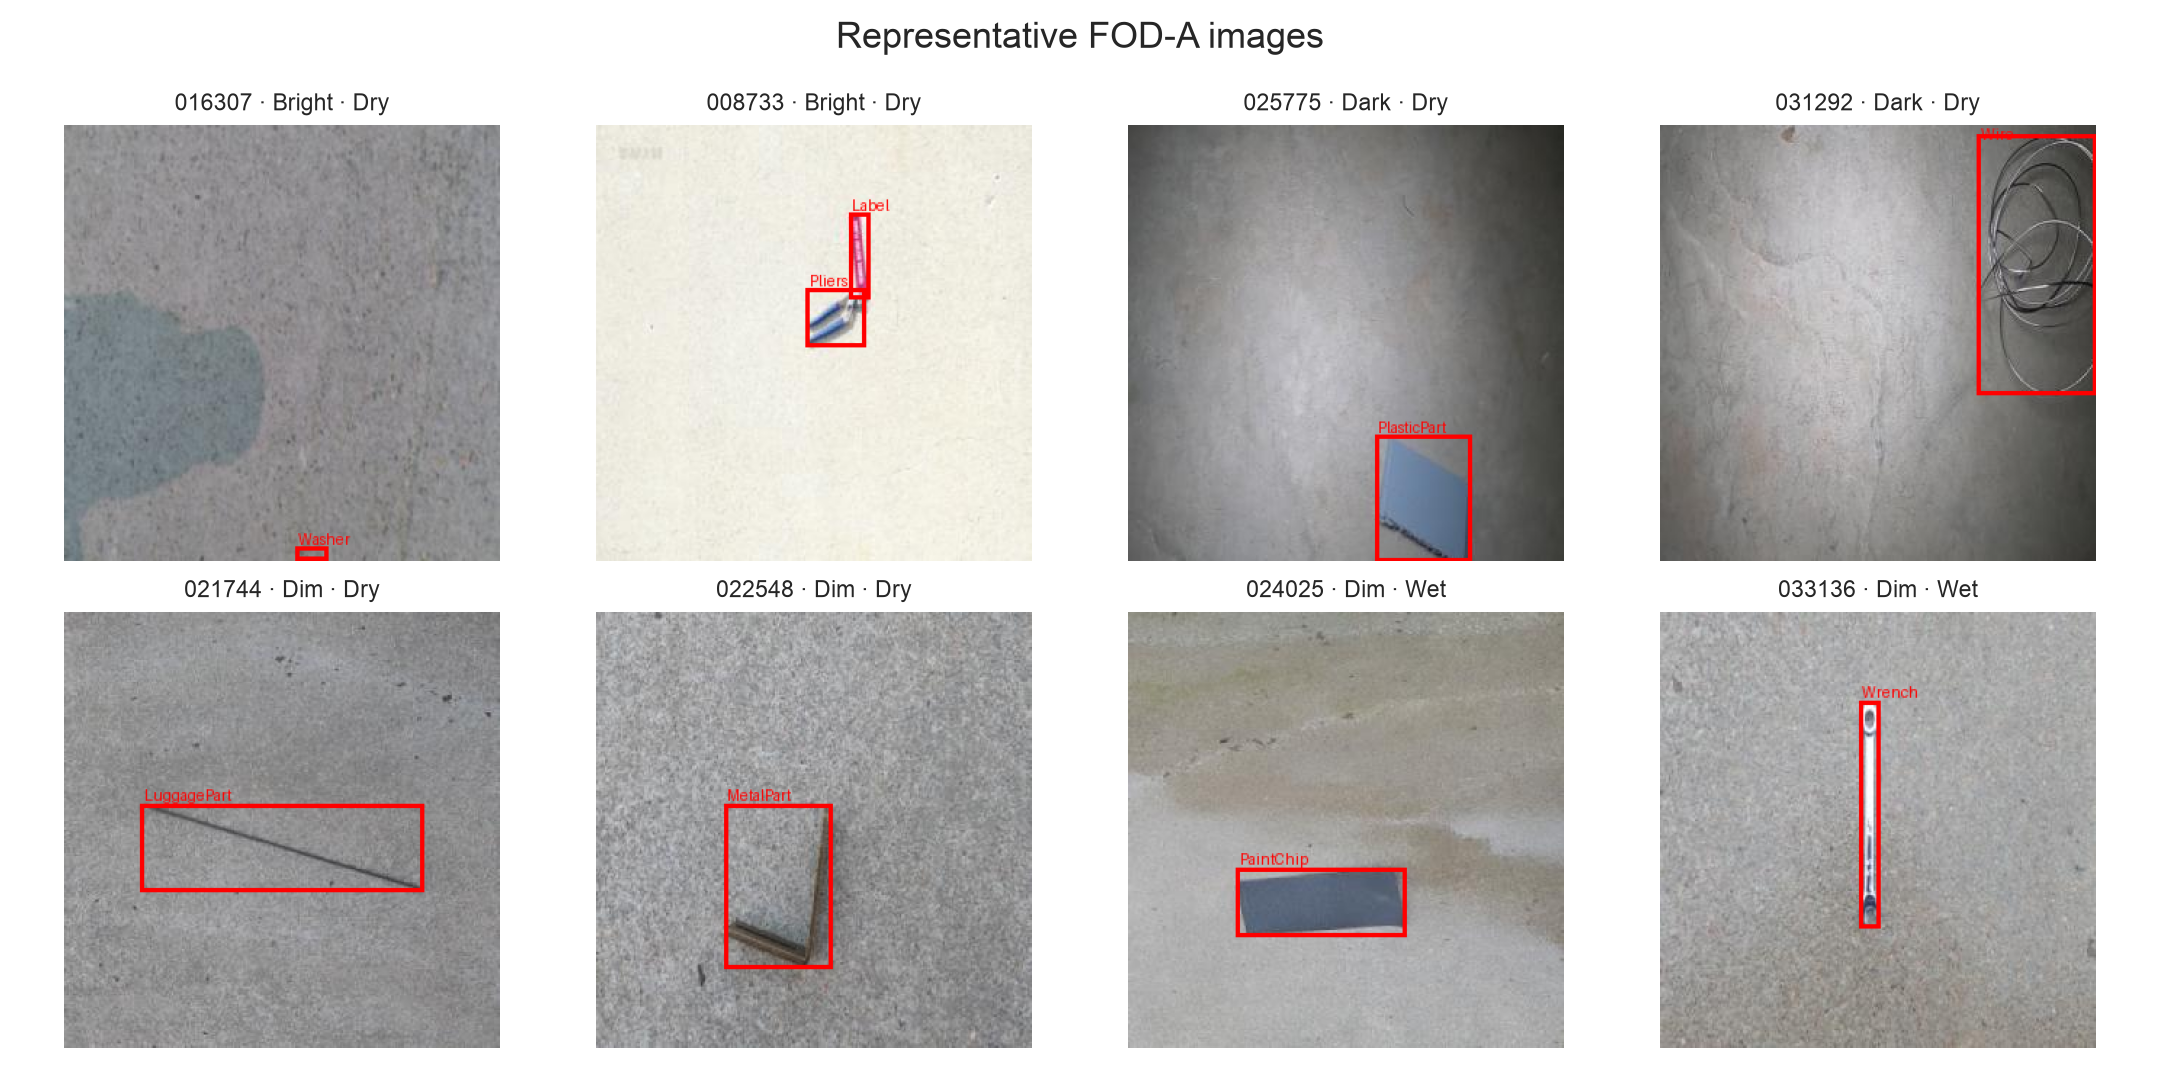

In [10]:
display(Image(filename=FIGURE_DIR / 'representative_images.png'))

## 8. Potentially difficult examples

These examples are selected reproducibly from the smallest annotated boxes, lowest-contrast images and adverse dim, dark or wet conditions. They are not model errors yet; they are evidence-based candidates for later failure analysis.

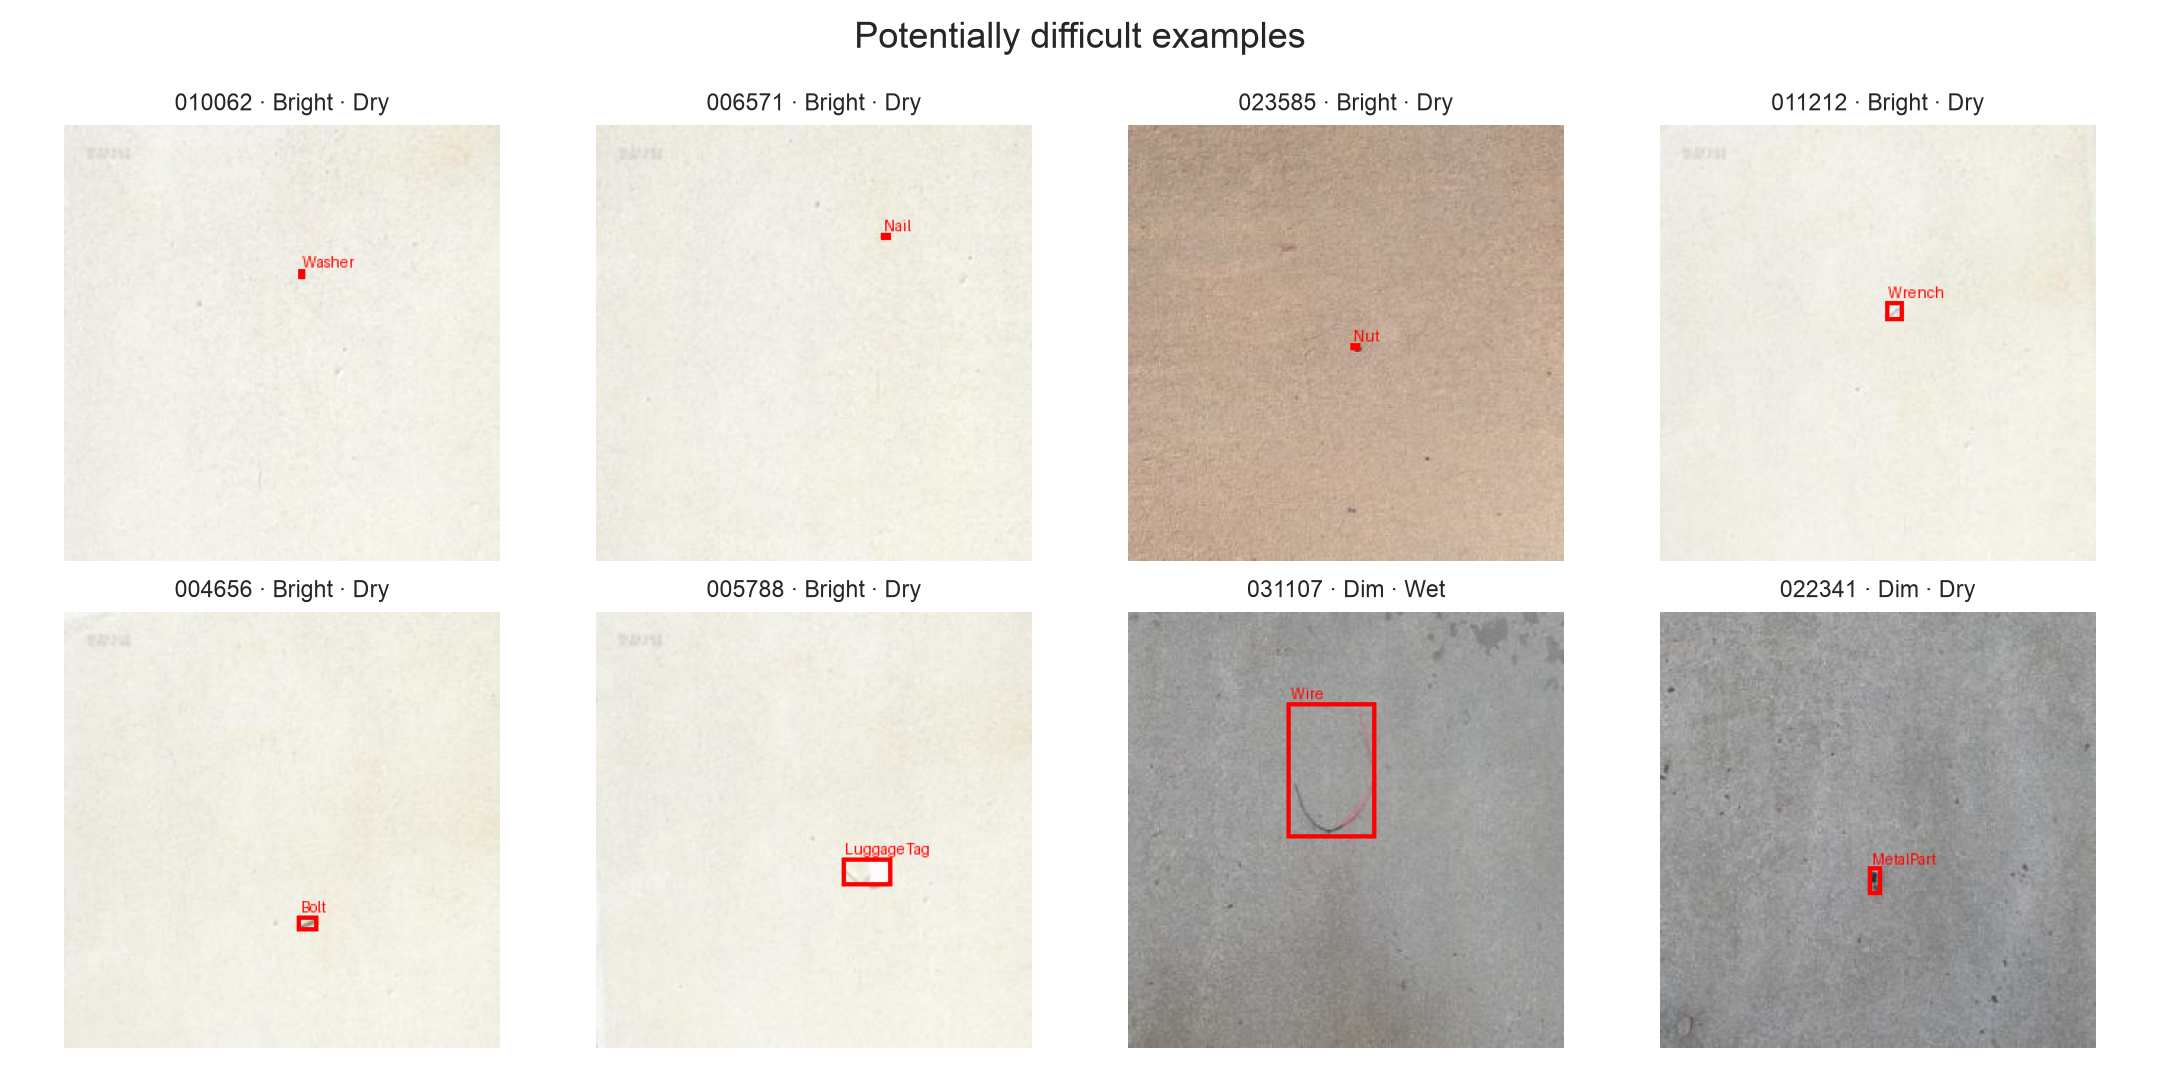

In [11]:
display(Image(filename=FIGURE_DIR / 'difficult_examples.png'))

## 9. Evidence-based implications

1. **Single-class primary detector:** the 31 source categories are imbalanced and FOD localisation is the common safety task.
2. **Multiscale evaluation:** the substantial small-object subset requires size-stratified precision and recall.
3. **Condition-aware evaluation:** bright, dim, dark, dry and wet results must be reported separately.
4. **Controlled preprocessing:** contrast enhancement should be tested particularly on low-contrast, dim and dark subsets rather than assumed to help every image.
5. **Leakage-resistant split:** strong class–environment associations and sequential capture patterns justify the group-aware partitioning completed before this analysis.
6. **Failure analysis:** false negatives on small and low-contrast FOD will receive special attention because they carry the greatest operational risk.